This notebook attempts to use the kernel on an unweighted graph, comparing two OSMNX maps whose street lenght has been transformed to a random values

In [49]:
import sys, pathlib
sys.path.append(str(pathlib.Path().resolve().parent))
from src.graph_utils import plot_weighted_graph, compute_Q, ktte,kttw
from src.graph_dataset_preparation import load_mutag, add_uniform_weights, ensure_unique_edge_weights
import networkx as nx
import random

In [50]:
import osmnx as ox

# Center point (latitude, longitude)
center_point = (6.2086, -75.5658)  # Medellín (El Poblado-ish)

# Get a 2 km radius drivable network
G1 = ox.graph_from_point(
    center_point,
    dist=500,          # meters
    network_type="drive",
    simplify=True
)

print(type(G1))
print(len(G1.nodes), "nodes")
print(len(G1.edges), "edges")


<class 'networkx.classes.multidigraph.MultiDiGraph'>
129 nodes
221 edges


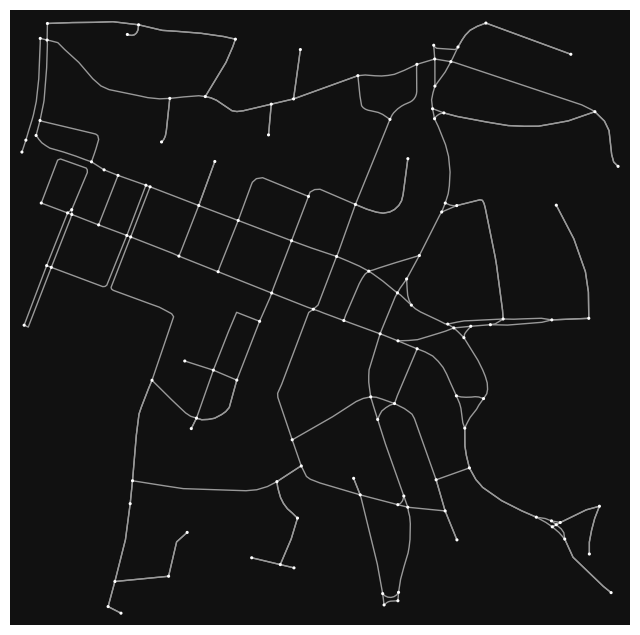

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [45]:
ox.plot_graph(G1, node_size=5)

In [51]:
# Center point (latitude, longitude)
center_point = (6.2083, -75.5656)  # Medellín (El Poblado-ish)

# Get a 2 km radius drivable network
G2 = ox.graph_from_point(
    center_point,
    dist=500,          # meters
    network_type="drive",
    simplify=True
)

print(type(G2))
print(len(G2.nodes), "nodes")
print(len(G2.edges), "edges")

<class 'networkx.classes.multidigraph.MultiDiGraph'>
120 nodes
207 edges


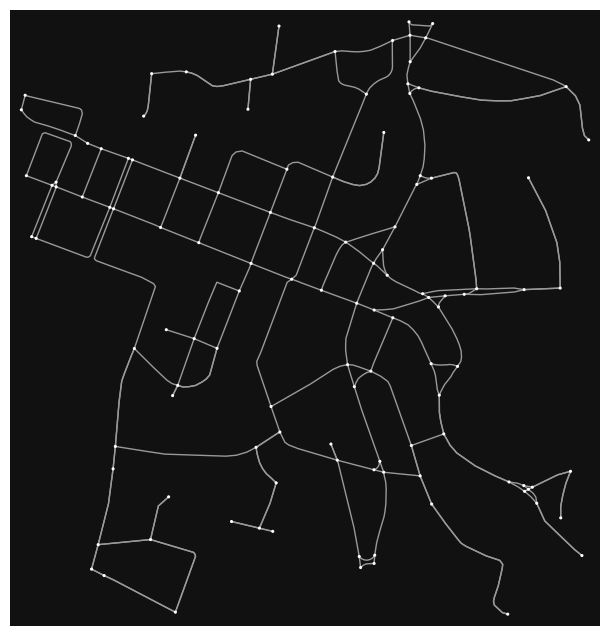

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [43]:
ox.plot_graph(G2, node_size=5)

In [52]:
G1_und = G1.to_undirected()
G2_und = G2.to_undirected()


In [53]:
Gu1 = nx.Graph()

for u, v, data in G1_und.edges(data=True):
    length = data.get("length", 1.0)
    if Gu1.has_edge(u, v):
        Gu1[u][v]["weight"] += length
    else:
        Gu1.add_edge(u, v, weight=length)


In [54]:
for u, v, data in Gu1.edges(data=True):
    print(f"{u} -> {v}, weight = {data.get('weight')}")


309026274 -> 416048073, weight = 6.740812596354091
309026274 -> 416048719, weight = 183.01550315460287
309026274 -> 309028467, weight = 87.05272126515705
309026274 -> 416055580, weight = 48.77672305644831
416048073 -> 313795802, weight = 310.53606377008543
416048073 -> 416031559, weight = 84.03525753782256
416048073 -> 416048074, weight = 87.10853584538627
416048719 -> 416048977, weight = 8.02357119046533
416048719 -> 9713081370, weight = 91.85588342304533
416048719 -> 416048978, weight = 111.05084416717978
309028467 -> 309028468, weight = 47.913716573200865
309028467 -> 416048074, weight = 7.228547345905173
416055580 -> 309028468, weight = 86.15276769357929
416055580 -> 9713081370, weight = 46.60996405861138
309026275 -> 309026276, weight = 93.4005947603494
309026275 -> 416031559, weight = 68.37608941056067
309026275 -> 416032601, weight = 89.17144692276453
309026276 -> 309026277, weight = 72.4717633610032
309026276 -> 309028164, weight = 90.67108732307997
309026276 -> 416099644, weig

In [55]:
def to_uniform_weighted_simple_graph(G, rng):
    H = nx.Graph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from(G.to_undirected().edges())
    for u, v in H.edges():
        H[u][v]["weight"] = rng.random()
    return H

rng = random.Random(42)
G1_und = to_uniform_weighted_simple_graph(G1_und, rng)
G2_und = to_uniform_weighted_simple_graph(G2_und, rng)


In [56]:
Gu1_unique = ensure_unique_edge_weights([G1_und])
Gu2_unique = ensure_unique_edge_weights([G2_und])

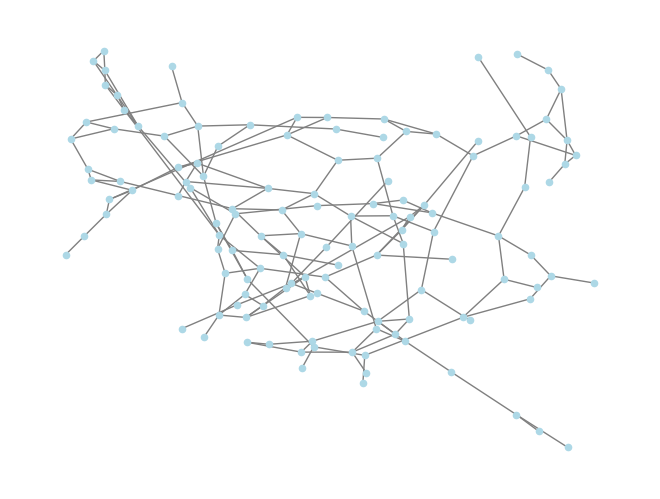

In [57]:
plot_weighted_graph(Gu1_unique[0])

In [58]:
Q1 = compute_Q(Gu1_unique[0])
Q2 = compute_Q(Gu2_unique[0])


In [59]:
kt = ktte(Q1,Q2, gamma=0.001)

Forbenius Product 1942.1730732345884


In [60]:
kt

np.float64(0.1433920096278864)

In [61]:
ktw = kttw(Q1,Q2, gamma=0.001)


In [62]:
ktw

np.float64(0.9419556682161476)